# Batch 18 | Entrained-flow coal gasifier: solver from first principles

This notebook is a live, executable explanation of the BYU atmospheric gasifier case. It builds the model in order: inputs → thermodynamics → coal devolatilization → char reactions → gas reactions → axial solution → radial extension → validation and diagnostics.

**How to present it:** run one section at a time, pause at the equations, and use the questions at the end as viva practice. Inputs and fitted parameters are taken from Mularski & Modlinski (2021); the solver is a transparent reduced-order implementation. A paper parameter is not the same thing as reproducing the paper's complete CFD implementation.

**Model boundary:** the paper's calculations used a commercial CFD framework with turbulent flow, particle tracking, radiation, and coupled chemistry. This notebook implements the Batch 18 model: ideal-gas properties with constant heat capacities, a plug-flow chemistry solver, and an annular radial-mixing extension. It does not claim to recreate Fluent or the paper's complete CFD solution.

> Before a live demonstration, select the notebook's Python kernel and use **Run All**. The radial grid defaults to a coarse interactive setting; increase `NR` and `NZ` in its cell for a smoother map if the computer allows it.

> **Kernel:** choose **Batch18 (Python 3.11)** in the notebook kernel picker. This project kernel uses compatible NumPy, SciPy, Pandas, and Matplotlib builds. The default Anaconda `base` kernel on this computer has a binary mismatch and raises `numpy.dtype size changed`. The data-path setup searches the current folder and its parents, so the notebook can be opened from the project, its `notebooks` folder, or the workspace parent.

## 1. The physical problem and the model map

An entrained-flow gasifier sends pulverized coal and an oxygen/steam stream through a hot reactor. Coal first heats and releases volatile matter. Volatiles react in the gas. The remaining carbon (char) reacts with oxygen, carbon dioxide, and steam. The products include hydrogen-rich synthesis gas (mainly H₂ and CO), carbon dioxide, water, and inert gases.

We solve a **steady** problem. The notebook presents one complete solver through two spatial views. The cross-section-averaged 1-D calculation describes axial change with one state per location `z`. The radial 2-D calculation uses the same chemistry while resolving the coaxial inlet streams and radial exchange. These names describe model dimensions, not separate project phases or separate assignments. The state contains gas molar flows, char mass flow, and raw-coal mass flow. Temperature is recovered from the adiabatic enthalpy balance rather than being an independent differential equation.

For the radial 2-D view, the circular cross-section is divided into annuli. Distinct primary and secondary inlet profiles feed reacting lanes. An assumed radial turbulent-diffusion closure exchanges species and heat between neighbors. This creates radial profiles, but it still does not solve radial momentum, turbulence, particle trajectories, recirculation, or radiation.

| Stage | Main question answered |
|---|---|
| Case and streams | What enters the reactor, and at what rate? |
| Element bookkeeping | Where can coal C, H, O, and N atoms go? |
| Kinetics | How fast are volatile release, char conversion, and gas reactions? |
| Enthalpy closure | What temperature is consistent with the energy inventory? |
| ODE integration | How do flows change down the reactor? |
| Annular extension | How do inlet segregation and radial exchange change the field? |
| Validation | How far are model predictions from digitized measurements? |

## 2. Imports and units

We use NumPy for arrays, SciPy's stiff ODE integrator for fast chemistry, Pandas for digitized measurements, and Matplotlib for figures. SI units are used internally: metres, seconds, kilograms, pascals, kelvin, and joules. Gas rates are mol/s; local gas concentrations used in the empirical global rates are kmol/m³, matching those rate definitions.

In [1]:
import math
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.linalg import solve_banded
from pathlib import Path

R = 8.314462618       # J mol-1 K-1
T_REF = 298.15        # K
P = 101325.0          # Pa
cwd = Path.cwd().resolve()
candidates=[]
for folder in (cwd,*cwd.parents):
    candidates.extend((folder,folder/"Batch18"))
ROOT = next((folder for folder in candidates
             if (folder/"case"/"byu_case.yaml").exists()),None)
if ROOT is None:
    raise FileNotFoundError("Could not find Batch18/case/byu_case.yaml from the notebook's working folder.")
print("Batch18 data folder:", ROOT)

Batch18 data folder: D:\hydrogen\Batch18


## 3. Reference case: geometry, feed streams, and coal

The vessel is 0.20 m in diameter and 1.80 m long at atmospheric pressure. The primary stream contains 85.0 mol% O₂, 12.6% Ar, and 2.4% H₂O at 400 K. The secondary stream is steam at 473 K. Utah bituminous coal enters with the primary stream at 23.88 kg/h. The coal analyses below distinguish **as-received proximate analysis** (moisture, volatile matter, fixed carbon, ash) from **dry-ash-free ultimate analysis** (elemental composition excluding moisture and ash).

The case uses the published 36 μm representative particle diameter for the main simulation. Its physical particle size distribution is examined later as a separate sensitivity diagnostic. Coal particle density is a stated engineering assumption.

In [2]:
case = {
    "diameter_m": 0.200, "length_m": 1.800, "pressure_Pa": P,
    "coal_kg_s": 23.88 / 3600.0,
    "primary_kg_s": 26.24 / 3600.0, "primary_T_K": 400.0,
    "primary_x": {"O2": 0.850, "Ar": 0.126, "H2O": 0.024},
    "secondary_kg_s": 6.62 / 3600.0, "secondary_T_K": 473.0,
    "secondary_x": {"H2O": 1.000},
    "proximate_wt_pct": {"moisture": 2.4, "volatile_matter": 45.6,
                          "fixed_carbon": 43.7, "ash": 8.3},
    "ultimate_daf_wt_pct": {"C": 77.6, "H": 6.56, "N": 1.42,
                            "S": 0.55, "O": 13.87},
    "particle_diameter_m": 36e-6, "particle_density_kg_m3": 1300.0,
    "ignition_temperature_K": 1400.0,
}

# Molecular weights (kg/mol), formation enthalpies at 298.15 K (J/mol),
# constant molar heat capacities (J/mol/K), and atom counts.
species = {
 "O2":  (0.031998,       0.0, 34.0, {"O":2}),
 "N2":  (0.028014,       0.0, 32.0, {"N":2}),
 "Ar":  (0.039948,       0.0, 20.8, {"Ar":1}),
 "H2":  (0.0020159,      0.0, 30.0, {"H":2}),
 "H2O": (0.0180153, -241826.0, 43.0, {"H":2,"O":1}),
 "CO":  (0.0280101,-110525.0, 33.0, {"C":1,"O":1}),
 "CO2": (0.0440095,-393522.0, 52.0, {"C":1,"O":2}),
 "CH4": (0.0160425, -74873.0, 60.0, {"C":1,"H":4}),
}
GAS = list(species)
IDX = {name:i for i,name in enumerate(GAS)}
M_C, M_H, M_O, M_N = 0.012011, 0.001008, 0.015999, 0.014007
CHAR_MW = M_C

fuel = case["coal_kg_s"]
prox = case["proximate_wt_pct"]
ultimate = case["ultimate_daf_wt_pct"]
case["ash_kg_s"] = fuel * prox["ash"] / 100
case["moisture_kg_s"] = fuel * prox["moisture"] / 100
case["daf_kg_s"] = fuel * (prox["volatile_matter"] + prox["fixed_carbon"]) / 100
case["daf_y"] = {e:v/sum(ultimate.values()) for e,v in ultimate.items()}
case["area_m2"] = math.pi * case["diameter_m"]**2 / 4

def stream_moles(mass_flow, composition):
    """Convert a gas mass flow and mole fractions to species molar flows."""
    mean_mw = sum(composition[s] * species[s][0] for s in composition)
    total_mol_s = mass_flow / mean_mw
    return {s: total_mol_s*x for s,x in composition.items()}

inlet = {s:0.0 for s in GAS}
for mdot, comp in [(case["primary_kg_s"],case["primary_x"]),
                   (case["secondary_kg_s"],case["secondary_x"])]:
    for s,n in stream_moles(mdot,comp).items(): inlet[s] += n
# The model treats moisture as immediately evaporated and adds it as inlet steam.
inlet["H2O"] += case["moisture_kg_s"] / species["H2O"][0]
case["inlet_moles"] = inlet
case["inlet_T_K"] = ((case["primary_kg_s"]*case["primary_T_K"]+
                       case["secondary_kg_s"]*case["secondary_T_K"])
                      /(case["primary_kg_s"]+case["secondary_kg_s"]))

print(f"Vessel: {case['diameter_m']:.2f} m dia × {case['length_m']:.2f} m; P={P/1e5:.4f} bar")
print(f"Coal: {fuel*3600:.2f} kg/h as received; {case['daf_kg_s']*3600:.2f} kg/h dry ash free")
print(f"Mass-weighted inlet gas temperature: {case['inlet_T_K']:.1f} K")
pd.Series(inlet, name="inlet mol/s").to_frame()

Vessel: 0.20 m dia × 1.80 m; P=1.0132 bar
Coal: 23.88 kg/h as received; 21.32 kg/h dry ash free
Mass-weighted inlet gas temperature: 414.7 K


,inlet mol/s
O2,0.189675
N2,0.000000
Ar,0.028116
H2,0.000000
H2O,0.116266
CO,0.000000
CO2,0.000000
CH4,0.000000


### Why convert mass flow to molar flow?

Reaction stoichiometry counts molecules and atoms, so chemistry is naturally written with molar flows. A stream with mass rate `m_dot` and mean molecular weight `MW_mix` has total molar rate `n_dot = m_dot / MW_mix`. Mole fractions distribute that total among the species. Keeping a single unit convention avoids a common error: mixing kg/s rates with molar stoichiometric coefficients.

## 4. Coal heating value and enthalpy model

For the fuel's unreported heating value, this case uses the Channiwala correlation with the DAF elemental percentages. The fuel formation enthalpy is backed out from its heating value and the complete-combustion products. Each gas enthalpy is `h_i(T) = Δh_f,i° + cp_i (T − Tref)`. This constant-`cp` approximation is simple and transparent, but less accurate at high temperature than temperature-dependent NASA polynomials.

The adiabatic energy closure says total enthalpy flow remains constant along a streamline. At each ODE evaluation, we solve `H(state,T) = H_in` for `T` with a bracketed root finder. That turns chemical formation enthalpy changes into temperature rise or fall without adding a separate energy source equation.

In [3]:
def h_species(s, T):
    mw, hf, cp, _ = species[s]
    return hf + cp*(T-T_REF)  # J/mol

def hhv_channiwala(y):
    # Correlation returns MJ/kg when inputs are mass percentages.
    return (0.3516*y["C"] + 1.16225*y["H"] - 0.1109*y["O"]
            + 0.0628*y["N"] + 0.10465*y["S"])*1e6

def coal_formation_enthalpy(hhv, y):
    nco2 = y["C"]/100/M_C
    nh2o = y["H"]/100/(2*M_H)
    products = nco2*(-393522.0) + nh2o*(-285830.0)  # liquid water for HHV
    return products + hhv  # J/kg daf

case["hhv_J_kg"] = hhv_channiwala(ultimate)
case["coal_hf_J_kg"] = coal_formation_enthalpy(case["hhv_J_kg"], ultimate)
print(f"Estimated DAF HHV: {case['hhv_J_kg']/1e6:.2f} MJ/kg")
print(f"Coal formation enthalpy: {case['coal_hf_J_kg']/1e6:.2f} MJ/kg")

Estimated DAF HHV: 33.52 MJ/kg
Coal formation enthalpy: -1.21 MJ/kg


## 5. Devolatilization: competing two-step model (C2SM)

The C2SM treats raw coal as reacting through two parallel Arrhenius paths. One path has a lower volatile yield and the other a higher yield. Each path has `kᵢ = Aᵢ exp(−Eᵢ/RTp)` and yield `αᵢ`. Thus the volatile release and char formation depend on particle temperature, rather than assuming a fixed proximate volatile fraction is released during the reactor calculation.

The constants below are those reported in Table 5 of the reference paper. The paper used FG-DVC to fit them; this notebook applies the reported constants and does not execute FG-DVC or repeat that fit.

The volatile gas split is underdetermined by elemental balances alone: three element equations (C, H, O) cannot uniquely determine five species (CO, CO₂, CH₄, H₂, H₂O). Therefore the code states two allocation assumptions explicitly. Any excess volatile carbon is retained with the solid carbon pool as a tar/soot surrogate. This preserves carbon atoms, while remaining a simplification relative to the paper's explicit tar treatment.

In [4]:
A1, E1, alpha1 = 4.269e4, 3.71e7/1000, 0.246  # s-1, J/mol, yield
A2, E2, alpha2 = 9.785e6, 8.993e7/1000, 0.931
SPLIT_O_TO_CO = 1.0
SPLIT_H_TO_CH4 = 0.5

def devol_rates(m_raw, Tp):
    """Return volatile and primary char mass-release rates [kg/s]."""
    Tp = max(float(Tp),300.0)
    k1 = A1*math.exp(-E1/(R*Tp)); k2 = A2*math.exp(-E2/(R*Tp))
    return ((alpha1*k1+alpha2*k2)*m_raw,
            ((1-alpha1)*k1+(1-alpha2)*k2)*m_raw)

def volatile_partition(dm_daf, dm_char, y):
    """Allocate coal atoms to gases and residual carbon; rates are per m of z."""
    if dm_daf <= 0: return {s:0.0 for s in GAS}, 0.0
    nC, nH, nO, nN = (dm_daf*y[e]/M for e,M in
                      [("C",M_C),("H",M_H),("O",M_O),("N",M_N)])
    nC_char = min(dm_char/M_C,nC)
    nC_vol = nC-nC_char
    nCO = min(SPLIT_O_TO_CO*nO,nC_vol)
    nO_left = nO-nCO
    nCO2 = min((1-SPLIT_O_TO_CO)*nO_left/2 if SPLIT_O_TO_CO<1 else 0,
               max(nC_vol-nCO,0))
    nO_left -= 2*nCO2
    nH_left = max(nH-2*nO_left,0)
    C_left = max(nC_vol-nCO-nCO2,0)
    nCH4 = min(SPLIT_H_TO_CH4*nH_left/4,C_left)
    nH2 = max((nH_left-4*nCH4)/2,0)
    soot_kg = max(C_left-nCH4,0)*M_C
    return {"CO":nCO,"CO2":nCO2,"CH4":nCH4,"H2":nH2,
            "H2O":max(nO_left,0),"N2":nN/2}, soot_kg

v_rate,c_rate=devol_rates(1.0,1800.0)
print(f"At Tp=1800 K, potential volatile yield={v_rate/(v_rate+c_rate):.3f}; char yield={c_rate/(v_rate+c_rate):.3f}")

At Tp=1800 K, potential volatile yield=0.842; char yield=0.158


## 6. Char conversion: kinetics and external diffusion in series

Char is represented as pure carbon. Three surface reactions are included:

1. `C + ½O₂ → CO` — exothermic oxidation.
2. `C + CO₂ → 2CO` — endothermic Boudouard gasification.
3. `C + H₂O → CO + H₂` — endothermic steam gasification, which produces hydrogen.

For each reaction the intrinsic surface coefficient is Arrhenius-like, `kₛ = A Tᵝ exp(−E/RTp)`. A gas-film diffusion coefficient `k_d` is combined in series: `k_eff = k_d kₛ/(k_d+kₛ)`. The smaller resistance controls the rate. The values shown are the paper's fitted kinetic-diffusion parameters for the BYU case. They are model-specific fitted values, not universal coal properties. External particle area is held fixed as char burns.

In [5]:
C_DIFF = 5.0e-12
char_rx = {
 "C_O2":  {"A":1.298e-3,"E":1.324e8/1000,"beta":1.233,"oxidizer":"O2","ox_per_C":0.5,"prod":{"CO":1.0}},
 "C_CO2": {"A":0.066,   "E":1.385e8/1000,"beta":-0.263,"oxidizer":"CO2","ox_per_C":1.0,"prod":{"CO":2.0}},
 "C_H2O": {"A":1.877e-3,"E":1.588e8/1000,"beta":-0.124,"oxidizer":"H2O","ox_per_C":1.0,"prod":{"CO":1.0,"H2":1.0}},
}

def char_rate(name,Tg,Tp,dp,p_ox,area):
    if p_ox<=0 or area<=0: return 0.0
    kd=C_DIFF*(0.5*(Tg+Tp))**0.75/max(dp,1e-9)
    rx=char_rx[name]
    ks=rx["A"]*max(Tp,300.0)**rx["beta"]*math.exp(-rx["E"]/(R*max(Tp,300.0)))
    return (kd*ks/(kd+ks+1e-30))*area*p_ox  # kg C/s (per axial length in solver)

print("Included char reactions:", ", ".join(char_rx))

Included char reactions: C_O2, C_CO2, C_H2O


## 7. Gas-phase chemistry: four global reactions

The homogeneous gas set includes CO oxidation, H₂ oxidation, reversible water-gas shift (WGS), and steam methane reforming. WGS redistributes CO/H₂O into CO₂/H₂; methane reforming is endothermic and produces hydrogen. The WGS net rate is multiplied by `1 − Q/Kp`, so its sign reverses when the reaction quotient passes equilibrium.

These are global rate expressions in the project model, not a detailed elementary reaction mechanism. The paper additionally couples chemistry with turbulent mixing through an eddy-dissipation-concept closure. The cross-section-averaged 1-D calculation has no turbulence field and uses the Arrhenius global rates directly. The radial 2-D calculation retains that same chemistry and adds radial species/heat exchange.

In [6]:
gas_rx = [
 {"name":"CO oxidation","A":2.239e12,"E":1.70e5,"orders":{"CO":1,"O2":0.25,"H2O":0.5},"nu":{"CO":-1,"O2":-0.5,"CO2":1},"dH":-282990.0,"rev":False},
 {"name":"H2 oxidation","A":1.000e14,"E":1.70e5,"orders":{"H2":1,"O2":0.5},"nu":{"H2":-1,"O2":-0.5,"H2O":1},"dH":-241826.0,"rev":False},
 {"name":"water-gas shift","A":2.75e9,"E":8.40e4,"orders":{"CO":1,"H2O":1},"nu":{"CO":-1,"H2O":-1,"CO2":1,"H2":1},"dH":-41200.0,"rev":True},
 {"name":"methane reforming","A":3.00e8,"E":1.26e5,"orders":{"CH4":1,"H2O":1},"nu":{"CH4":-1,"H2O":-1,"CO":1,"H2":3},"dH":206000.0,"rev":False},
]

def wgs_Kp(T): return math.exp(4577.8/max(T,300.0)-4.33)

def gas_sources(conc,T):
    """Return gas source rates [kmol m-3 s-1]; concentrations use kmol/m3."""
    src={s:0.0 for s in GAS}
    for rx in gas_rx:
        rate=rx["A"]*math.exp(-rx["E"]/(R*max(T,300.0)))
        for s,order in rx["orders"].items(): rate*=max(conc.get(s,0),0)**order
        if rx["rev"]:
            q=(max(conc["CO2"],0)*max(conc["H2"],0))/max(conc["CO"]*conc["H2O"],1e-30)
            rate*=1-q/wgs_Kp(T)
        for s,nu in rx["nu"].items(): src[s]+=nu*rate
    return src

## 8. Assemble the cross-section-averaged 1-D solver

For each species, the axial derivative is the sum of homogeneous reaction production and heterogeneous particle-surface production. The raw-coal equation loses mass as it devolatilizes; the char equation gains devolatilization char and loses carbon through char reactions. In a plug-flow balance, converting a volumetric reaction source into a derivative per metre uses `volume per axial length = cross-sectional area`.

The ideal-gas law estimates density. Superficial velocity is `u = gas mass flow/(ρ A)`. We assume particles move at that velocity and the gas and particles share one temperature. The system is stiff because reaction rates can change rapidly with temperature, so we use LSODA, which switches between stiff and non-stiff integration methods.

In [7]:
N_GAS=len(GAS)
I_CHAR=N_GAS
I_RAW=N_GAS+1

def stream_enthalpy(state,T,local_case=case):
    H=sum(max(state[i],0)*h_species(s,T) for i,s in enumerate(GAS))
    H += max(state[I_CHAR],0)/CHAR_MW*21.0*(T-T_REF)
    H += max(state[I_RAW],0)*(case["coal_hf_J_kg"]+1200.0*(T-T_REF))
    H += local_case["ash_kg_s"]*900.0*(T-T_REF)
    return H

def temperature_from_enthalpy(state,Htarget,local_case=case):
    fn=lambda T: stream_enthalpy(state,T,local_case)-Htarget
    lo,hi=280.0,4000.0
    flo,fhi=fn(lo),fn(hi)
    if not np.isfinite(flo+fhi) or np.signbit(flo)==np.signbit(fhi):
        return lo if abs(flo)<abs(fhi) else hi
    return brentq(fn,lo,hi,xtol=0.05)

def mean_mw(x): return sum(x[s]*species[s][0] for s in GAS)

def rhs(z,state,H0,local_case):
    """Steady reacting plug-flow balances, derivatives with respect to z [m]."""
    y=np.maximum(state,0.0)
    ng={s:y[IDX[s]] for s in GAS}
    nt=sum(ng.values())
    dy=np.zeros_like(y)
    if nt<=1e-30: return dy
    T=float(np.clip(temperature_from_enthalpy(y,H0,local_case),280,3600))
    x={s:ng[s]/nt for s in GAS}
    mw=mean_mw(x)
    rho=P*mw/(R*T)
    mdot=sum(ng[s]*species[s][0] for s in GAS)
    u=max(mdot/(rho*local_case["area_m2"]),1e-3)
    # Convert molar flow [mol/s] to concentration [kmol/m3].
    conc={s:ng[s]/(u*local_case["area_m2"])/1000.0 for s in GAS}
    src=gas_sources(conc,T)
    for s in GAS: dy[IDX[s]] += src[s]*1000.0*local_case["area_m2"]

    mraw=y[I_RAW]
    if mraw>1e-12:
        vdot,cdot=devol_rates(mraw,T)
        dmraw_dz=-(vdot+cdot)/u
        dy[I_RAW]+=dmraw_dz
        dy[I_CHAR]+=cdot/u
        released,soot=volatile_partition(-dmraw_dz,cdot/u,local_case["daf_y"])
        for s,n in released.items(): dy[IDX[s]]+=n
        dy[I_CHAR]+=soot

    mchar=y[I_CHAR]
    if mchar>1e-12:
        # Number of particles per second from coal feed and representative dp.
        particle_mass=local_case["particle_density_kg_m3"]*math.pi/6*local_case["particle_diameter_m"]**3
        nparticle=local_case["coal_kg_s"]/particle_mass
        area_per_length=nparticle*math.pi*local_case["particle_diameter_m"]**2/u
        for name,rx in char_rx.items():
            pox=x[rx["oxidizer"]]*P
            rkg=char_rate(name,T,T,local_case["particle_diameter_m"],pox,area_per_length)
            rkg=min(rkg,mchar/u*50.0)
            if rkg<=0: continue
            nC=rkg/CHAR_MW
            dy[I_CHAR]-=rkg
            dy[IDX[rx["oxidizer"]]]-=nC*rx["ox_per_C"]
            for s,nu in rx["prod"].items(): dy[IDX[s]]+=nC*nu
    return dy

def solve_1d(local_case, n_out=180):
    y0=np.zeros(N_GAS+2)
    for s,n in local_case["inlet_moles"].items(): y0[IDX[s]]=n
    y0[I_RAW]=local_case["daf_kg_s"]  # all dry-ash-free coal enters un-devolatilized
    # Explicit ignition patch: raise the starting enthalpy to represent hot
    # flame anchoring/recirculation absent from the one-dimensional equations.
    Tstart=local_case["ignition_temperature_K"]
    H0=stream_enthalpy(y0,Tstart,local_case)
    Hcold=stream_enthalpy(y0,local_case["inlet_T_K"],local_case)
    z=np.linspace(0,local_case["length_m"],n_out)
    sol=solve_ivp(rhs,(0,local_case["length_m"]),y0,args=(H0,local_case),
                  method="LSODA",t_eval=z,rtol=1e-6,atol=1e-12,
                  max_step=local_case["length_m"]/200)
    if not sol.success: raise RuntimeError(sol.message)
    Y=np.maximum(sol.y,0.0)
    T=np.array([temperature_from_enthalpy(Y[:,k],H0,local_case) for k in range(len(z))])
    nmat=Y[:N_GAS]
    ntot=np.maximum(nmat.sum(axis=0),1e-30)
    return {"z":z,"T":T,"moles":{s:nmat[IDX[s]] for s in GAS},
            "x":{s:nmat[IDX[s]]/ntot for s in GAS},
            "m_char":Y[I_CHAR],"m_raw":Y[I_RAW],"H0":H0,
            "ignition_energy_W":H0-Hcold,"case":local_case}

result=solve_1d(case)
print(f"1-D calculation solved {len(result['z'])} axial stations.")
print(f"Peak / exit temperature: {result['T'].max():.0f} / {result['T'][-1]:.0f} K")
if result["T"].max() >= 3999.0:
    print("INTERPRETATION: the 4000 K peak is the temperature-recovery bracket ceiling; it is clipped, not a resolved peak prediction.")
print(f"Ignition enthalpy adjustment: {result['ignition_energy_W']/1000:.2f} kW")

1-D calculation solved 180 axial stations.
Peak / exit temperature: 4000 / 3029 K
INTERPRETATION: the 4000 K peak is the temperature-recovery bracket ceiling; it is clipped, not a resolved peak prediction.
Ignition enthalpy adjustment: 19.35 kW


### Ignition patch: explain what the number means

A cold, perfectly mixed one-dimensional stream has no recirculation or radiation to ignite it. The code therefore starts at the configured 1400 K and reports the additional enthalpy relative to the cold feed. This is a numerical stand-in for flame stabilization; it is not free energy or a resolved burner model. It can strongly affect predictions, so say so plainly when presenting results.

## 9. Read the 1-D calculation

Plot temperature, gas mole fractions, and remaining raw coal/char. The temperature peak shows where fast oxidation releases heat; downstream, endothermic char gasification and reforming can cool the gas while changing its H₂/CO composition. The four-gas chemistry and ignition treatment influence these trends, so the plots are model predictions to compare with measurements, not guaranteed reproduction of a CFD curve.

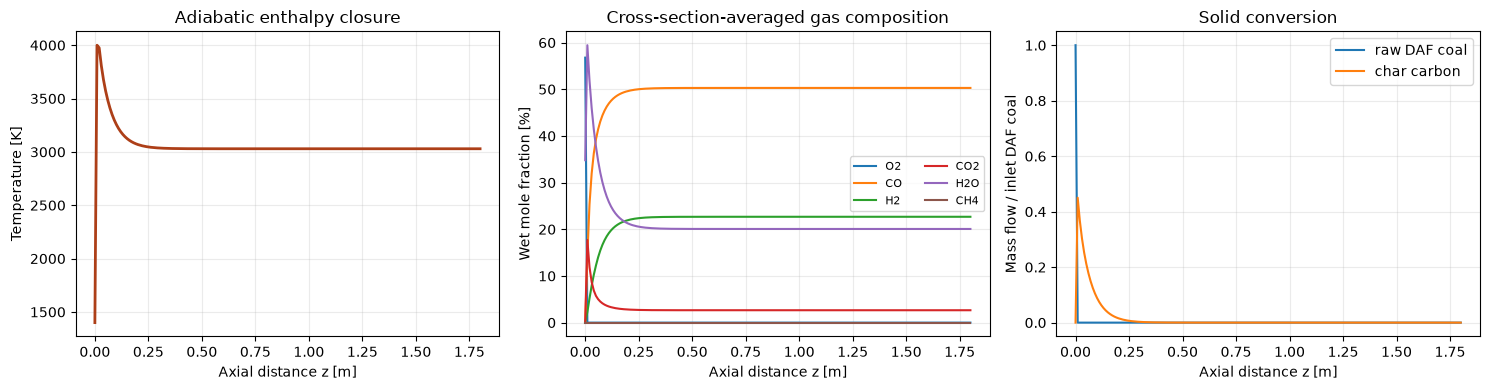

In [8]:
fig,axs=plt.subplots(1,3,figsize=(15,4))
axs[0].plot(result["z"],result["T"],color="#ad3f18",lw=2)
axs[0].set(xlabel="Axial distance z [m]",ylabel="Temperature [K]",title="Adiabatic enthalpy closure")
for s in ["O2","CO","H2","CO2","H2O","CH4"]:
    axs[1].plot(result["z"],100*result["x"][s],label=s)
axs[1].set(xlabel="Axial distance z [m]",ylabel="Wet mole fraction [%]",title="Cross-section-averaged gas composition")
axs[1].legend(ncol=2,fontsize=8)
axs[2].plot(result["z"],result["m_raw"]/case["daf_kg_s"],label="raw DAF coal")
axs[2].plot(result["z"],result["m_char"]/case["daf_kg_s"],label="char carbon")
axs[2].set(xlabel="Axial distance z [m]",ylabel="Mass flow / inlet DAF coal",title="Solid conversion")
axs[2].legend()
for ax in axs: ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 10. Conservation checks and useful performance indicators

An atom balance checks all model phases: gas, residual raw coal, and char. For each element, percent error is `(out − in)/in × 100`. Checking only gas would be wrong because carbon and fuel hydrogen can remain in the solids. Because the char pool is treated as carbon and ash is inert, elemental C/H/O/N in the DAF coal are counted explicitly; Ar comes only from the inlet.

Carbon conversion measures how much initial fuel carbon is no longer in raw coal or char. Cold-gas efficiency (CGE) compares syngas lower-heating-value energy at the outlet with fuel heating-value input. CGE uses the project's stated gas LHV basis and should be identified as a model metric, not a measured efficiency.

In [9]:
def atom_flows(gas_moles,char_moles=0.0,raw_kg_s=0.0):
    out={e:0.0 for e in ["C","H","O","N","Ar"]}
    for s,n in gas_moles.items():
        for e,count in species[s][3].items(): out[e]+=n*count
    out["C"]+=char_moles
    for e in ["C","H","O","N"]:
        out[e]+=raw_kg_s*case["daf_y"][e]/{"C":M_C,"H":M_H,"O":M_O,"N":M_N}[e]
    return out

gas_in={s:result["moles"][s][0] for s in GAS}
gas_out={s:result["moles"][s][-1] for s in GAS}
ein=atom_flows(gas_in,0.0,case["daf_kg_s"])
eout=atom_flows(gas_out,result["m_char"][-1]/CHAR_MW,result["m_raw"][-1])
balance=pd.DataFrame({"in mol atoms/s":ein,"out mol atoms/s":eout})
balance["error %"]=(balance["out mol atoms/s"]-balance["in mol atoms/s"])/balance["in mol atoms/s"].replace(0,np.nan)*100
display(balance)

c_in=case["daf_kg_s"]*case["daf_y"]["C"]
c_solid=result["m_char"][-1]+result["m_raw"][-1]*case["daf_y"]["C"]
carbon_conversion=1-c_solid/c_in
lhv={"H2":10.8e6*0.0224,"CO":12.6e6*0.0224,"CH4":35.8e6*0.0224} # J/mol
syngas_W=sum(result["moles"][s][-1]*v for s,v in lhv.items())
cge=syngas_W/(case["daf_kg_s"]*case["hhv_J_kg"])
print(f"Carbon conversion: {100*carbon_conversion:.1f}%")
print(f"Cold gas efficiency (stated LHV basis): {100*cge:.1f}%")

,in mol atoms/s,out mol atoms/s,error %
C,0.382706,0.382706,2.014729e-11
H,0.618034,0.618034,1.357073e-09
O,0.546969,0.546969,9.322754e-11
N,0.006005,0.006005,-4.188628e-13
Ar,0.028116,0.028116,0.000000e+00


Carbon conversion: 100.0%
Cold gas efficiency (stated LHV basis): 71.7%


## 11. Resolve the radial flow distribution

To represent the coaxial injector, divide the radius into finite-volume annuli. Primary gas and coal are concentrated inside the published 1.3 cm primary-nozzle diameter; secondary steam is concentrated between that radius and the 2.86 cm secondary-nozzle outside diameter. A small background fraction spreads each stream across the cross-section to avoid empty lanes. This spreading fraction is an explicit reduced-model assumption.

Each annulus uses the same 1-D chemistry equations to generate a baseline reaction history. At each axial step, that lane's atom-balanced chemistry increment is applied to the previously mixed state. A backward-Euler finite-volume diffusion step exchanges gas species between adjacent annuli, and a second conservative step exchanges heat. This is one integrated solver walkthrough: the 1-D calculation makes the axial equations easy to inspect, while the radial calculation applies those equations across all annuli and adds cross-stream transport. The mixing coefficient, Schmidt number, and Prandtl number form a closure; they are not measurements from the BYU experiment. The resulting 2-D fields still come from a reduced stream-tube model without a momentum equation, Lagrangian particle tracking, recirculation, or radiation.

In [10]:
# Interactive grid; increase both values for smoother demo maps.
NR, NZ = 12, 100
BACKGROUND_SPREAD = 0.20
MIXING_COEFFICIENT = 0.05
SCHMIDT_T, PRANDTL_T = 0.70, 0.90
MOLECULAR_D = 1.0e-5
D_MAX = 0.20

def radial_weights(r_faces, r_inner, r_outer, background):
    """Area-normalized weights for a solid core or annular injector stream."""
    areas=math.pi*(r_faces[1:]**2-r_faces[:-1]**2)
    total=areas.sum()
    overlap=math.pi*np.maximum(np.minimum(r_faces[1:],r_outer)**2-
                               np.maximum(r_faces[:-1],r_inner)**2,0.0)
    core=math.pi*(r_outer**2-r_inner**2)
    share=background*areas/total+(1-background)*overlap/core
    w=share/areas
    return w/np.dot(w,areas)

def make_annular_cases(nr):
    Rv=case["diameter_m"]/2
    r_faces=np.linspace(0,Rv,nr+1)
    areas=math.pi*(r_faces[1:]**2-r_faces[:-1]**2)
    wp=radial_weights(r_faces,0,0.013/2,BACKGROUND_SPREAD)
    ws=radial_weights(r_faces,0.013/2,0.0286/2,BACKGROUND_SPREAD)
    pflow=stream_moles(case["primary_kg_s"],case["primary_x"])
    sflow=stream_moles(case["secondary_kg_s"],case["secondary_x"])
    lanes=[]
    for j,Acell in enumerate(areas):
        c=deepcopy(case); c["area_m2"]=Acell
        c["coal_kg_s"]=case["coal_kg_s"]*wp[j]*Acell
        c["ash_kg_s"]=c["coal_kg_s"]*prox["ash"]/100
        c["moisture_kg_s"]=c["coal_kg_s"]*prox["moisture"]/100
        c["daf_kg_s"]=c["coal_kg_s"]*(prox["volatile_matter"]+prox["fixed_carbon"])/100
        c["inlet_moles"]={s:0.0 for s in GAS}
        for s,n in pflow.items(): c["inlet_moles"][s]+=n*wp[j]*Acell
        for s,n in sflow.items(): c["inlet_moles"][s]+=n*ws[j]*Acell
        c["inlet_moles"]["H2O"]+=c["moisture_kg_s"]/species["H2O"][0]
        pm=case["primary_kg_s"]*wp[j]*Acell
        sm=case["secondary_kg_s"]*ws[j]*Acell
        cm=c["coal_kg_s"]
        c["inlet_T_K"]=(pm*case["primary_T_K"]+sm*case["secondary_T_K"]+
                        cm*case["primary_T_K"])/max(pm+sm+cm,1e-30)
        lanes.append(c)
    return r_faces,areas,wp,ws,lanes

def lane_properties(y,H,local):
    ng=np.maximum(y[:N_GAS],0); total=ng.sum()
    if total<=1e-30:
        x={s:0.0 for s in GAS}; x["Ar"]=1.0; mw=species["Ar"][0]; T=local["inlet_T_K"]; mdot=0.0
    else:
        x={s:ng[IDX[s]]/total for s in GAS}; mw=mean_mw(x)
        T=float(np.clip(temperature_from_enthalpy(y,H,local),280,3600))
        mdot=sum(ng[IDX[s]]*species[s][0] for s in GAS)
    rho=P*mw/(R*T)
    u=mdot/max(rho*local["area_m2"],1e-30)
    return x,T,rho,max(u,1e-8)

def solve_radial(nr=NR,nz=NZ):
    r_faces,areas,wp,ws,lanes=make_annular_cases(nr)
    radius=0.5*(r_faces[:-1]+r_faces[1:]); z=np.linspace(0,case["length_m"],nz)
    base=np.zeros((nr,nz,N_GAS+3))
    for j,lc in enumerate(lanes):
        lane=solve_1d(lc,n_out=nz)
        for s in GAS: base[j,:,IDX[s]]=lane["moles"][s]
        base[j,:,I_CHAR]=lane["m_char"]; base[j,:,I_RAW]=lane["m_raw"]
        base[j,:,-1]=lane["H0"]

    state=np.zeros_like(base); state[:,0,:]=base[:,0,:]
    for k in range(1,nz):
        # Operator split: apply each lane's chemistry increment, retaining
        # nonnegative flows by scaling the whole local increment together.
        for j in range(nr):
            old=state[j,k-1,:N_GAS+2]
            delta=base[j,k,:N_GAS+2]-base[j,k-1,:N_GAS+2]
            falling=delta<0
            alpha=min(1.0,float(np.min(old[falling]/-delta[falling]))) if np.any(falling) else 1.0
            state[j,k,:N_GAS+2]=np.maximum(old+max(alpha,0)*delta,0)
            state[j,k,-1]=state[j,k-1,-1]
        props_j=[lane_properties(state[j,k,:N_GAS+2],state[j,k,-1],lanes[j]) for j in range(nr)]
        vel=np.array([p[3] for p in props_j])
        bulk_u=float(np.dot(vel,areas)/areas.sum())
        d_turb=min(MIXING_COEFFICIENT*bulk_u*(case["diameter_m"]/2),D_MAX)
        d_species=np.clip(d_turb/SCHMIDT_T+MOLECULAR_D,MOLECULAR_D,D_MAX)
        d_heat=np.clip(d_turb/PRANDTL_T+MOLECULAR_D,MOLECULAR_D,D_MAX)

        # Conservative implicit species diffusion between neighboring annuli.
        diag=np.zeros(nr); upper=np.zeros(nr-1); lower=np.zeros(nr-1); af=np.zeros(nr-1)
        dz=z[k]-z[k-1]
        for j in range(nr-1):
            af[j]=d_species*2*math.pi*r_faces[j+1]/(r_faces[j+1]-r_faces[j])
            vl=max(vel[j]*areas[j],1e-30); vr=max(vel[j+1]*areas[j+1],1e-30)
            diag[j]+=af[j]/vl; diag[j+1]+=af[j]/vr
            upper[j]=-dz*af[j]/vr; lower[j]=-dz*af[j]/vl
        ab=np.zeros((3,nr)); ab[0,1:]=upper; ab[1]=1+dz*diag; ab[2,:-1]=lower
        ya=state[:,k,:N_GAS].copy()
        yb=solve_banded((1,1),ab,ya,check_finite=False)

        # Carry the enthalpy of diffusing gas species across each face.
        H=state[:,k,-1].copy()
        for j in range(nr-1):
            vl=max(vel[j]*areas[j],1e-30); vr=max(vel[j+1]*areas[j+1],1e-30)
            flux=af[j]*(yb[j]/vl-yb[j+1]/vr)
            Tf=0.5*(props_j[j][1]+props_j[j+1][1])
            q=sum(flux[i]*h_species(s,Tf) for i,s in enumerate(GAS))
            H[j]-=dz*q; H[j+1]+=dz*q
        state[:,k,:N_GAS]=yb; state[:,k,-1]=H

        # Implicit, pairwise conservative turbulent heat conduction.
        props2=[lane_properties(state[j,k,:N_GAS+2],state[j,k,-1],lanes[j]) for j in range(nr)]
        T0=np.array([p[1] for p in props2]); rho=np.array([p[2] for p in props2])
        cap=np.zeros(nr); cp_mass=np.zeros(nr)
        for j in range(nr):
            yj=state[j,k,:N_GAS+2]
            cap[j]=sum(yj[i]*species[s][2] for i,s in enumerate(GAS))
            cap[j]+=yj[I_CHAR]/CHAR_MW*21.0+yj[I_RAW]*1200.0+lanes[j]["ash_kg_s"]*900.0
            md=sum(yj[i]*species[s][0] for i,s in enumerate(GAS))
            cp_mass[j]=sum(yj[i]*species[s][2] for i,s in enumerate(GAS))/max(md,1e-30)
        diag_h=np.zeros(nr); up_h=np.zeros(nr-1); low_h=np.zeros(nr-1)
        for j in range(nr-1):
            dr=r_faces[j+1]-r_faces[j]
            conduct=0.5*(rho[j]+rho[j+1])*d_heat*0.5*(cp_mass[j]+cp_mass[j+1])*2*math.pi*r_faces[j+1]/dr
            diag_h[j]+=conduct; diag_h[j+1]+=conduct
            up_h[j]=-dz*conduct; low_h[j]=-dz*conduct
        ab_h=np.zeros((3,nr)); ab_h[0,1:]=up_h
        ab_h[1]=np.maximum(cap,1e-12)+dz*diag_h; ab_h[2,:-1]=low_h
        Tnew=solve_banded((1,1),ab_h,np.maximum(cap,1e-12)*T0,check_finite=False)
        state[:,k,-1]+=cap*(Tnew-T0)

    T=np.zeros((nr,nz)); X={s:np.zeros((nr,nz)) for s in GAS}
    for j in range(nr):
        for k in range(nz):
            y=state[j,k,:N_GAS+2]; H=state[j,k,-1]
            T[j,k]=temperature_from_enthalpy(y,H,lanes[j])
            total=max(y[:N_GAS].sum(),1e-30)
            for s in GAS: X[s][j,k]=y[IDX[s]]/total
    mol={s:state[:,:,IDX[s]].sum(axis=0) for s in GAS}
    return {"r":radius,"r_faces":r_faces,"z":z,"T":T,"x":X,
            "state":state,"moles":mol,"m_char":state[:,:,I_CHAR].sum(axis=0),
            "m_raw":state[:,:,I_RAW].sum(axis=0),"areas":areas,
            "wp":wp,"ws":ws,"lanes":lanes}

result2=solve_radial(nr=NR,nz=NZ)
print(f"Radial calculation solved {NR} annuli × {NZ} axial stations.")
print(f"Peak field temperature: {result2['T'].max():.0f} K")
if result2["T"].max() >= 3999.0:
    print("INTERPRETATION: the 4000 K peak is the temperature-recovery bracket ceiling; it is clipped, not a resolved peak prediction.")
print(f"Primary/secondary radial feed weights each integrate to: "
      f"{np.dot(result2['wp'],result2['areas']):.6f}, {np.dot(result2['ws'],result2['areas']):.6f}")
gas_in_2={s:result2["moles"][s][0] for s in GAS}
gas_out_2={s:result2["moles"][s][-1] for s in GAS}
ein_2=atom_flows(gas_in_2,0.0,case["daf_kg_s"])
eout_2=atom_flows(gas_out_2,result2["m_char"][-1]/CHAR_MW,result2["m_raw"][-1])
balance_2=pd.DataFrame({"in mol atoms/s":ein_2,"out mol atoms/s":eout_2})
balance_2["error %"]=(balance_2["out mol atoms/s"]-balance_2["in mol atoms/s"])/balance_2["in mol atoms/s"].replace(0,np.nan)*100
print("Radial-model global atom balance (% error):")
display(balance_2[["error %"]])
csolid_2=result2["m_char"][-1]+result2["m_raw"][-1]*case["daf_y"]["C"]
conv_2=1-csolid_2/(case["daf_kg_s"]*case["daf_y"]["C"])
print(f"Radial-model carbon conversion: {100*conv_2:.1f}%")

Radial calculation solved 12 annuli × 100 axial stations.
Peak field temperature: 4000 K
INTERPRETATION: the 4000 K peak is the temperature-recovery bracket ceiling; it is clipped, not a resolved peak prediction.
Primary/secondary radial feed weights each integrate to: 1.000000, 1.000000
Radial-model global atom balance (% error):


,error %
C,2.713480e-07
H,2.537753e-08
O,7.398041e-09
N,3.176104e-08
Ar,8.637684e-14


Radial-model carbon conversion: 59.9%


## 12. Contours: read the two-dimensional solution

The contour plots show the radial field from the same chemistry and operating case, with coaxial inlet segregation and radial exchange represented. The primary lane starts oxygen-rich and the secondary lane starts steam-rich. The predicted radial differences depend strongly on the assumed stream spreading and mixing closure; discuss that dependence when interpreting the contours.

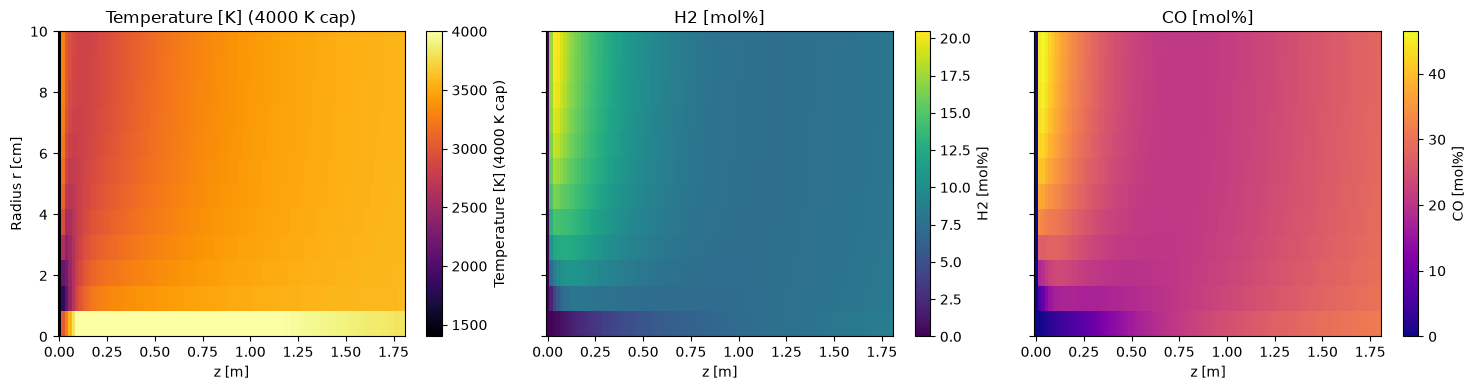

In [11]:
fig,axs=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,field,title,cmap in [(axs[0],result2["T"],"Temperature [K] (4000 K cap)","inferno"),
                            (axs[1],100*result2["x"]["H2"],"H2 [mol%]","viridis"),
                            (axs[2],100*result2["x"]["CO"],"CO [mol%]","plasma")]:
    im=ax.pcolormesh(result2["z"],result2["r"]*100,field,shading="auto",cmap=cmap)
    fig.colorbar(im,ax=ax,label=title); ax.set_xlabel("z [m]"); ax.set_title(title)
axs[0].set_ylabel("Radius r [cm]")
plt.tight_layout(); plt.show()

## 13. Compare predictions with digitized experimental markers

The validation CSVs hold approximate experimental markers digitized from published plots. They are not raw instrument files or the paper's CFD curves. We compare the model to the experimental markers and report absolute error in **percentage points**: an experimental value of 10% and a model value of 12% differ by 2 percentage points.

For the centerline comparison, the first radial annulus is the closest available model location to the axis. For radial profiles, model values are linearly interpolated in axial position and radius to the experimental marker locations. The source digitization uncertainty is about ±0.3 percentage point for the axial CSV and ±0.5 percentage point for radial markers, with additional coordinate uncertainty. Treat small differences accordingly. H₂O is plotted if present, but the source cautions that it was calculated by hydrogen balance and excludes it from the main radial scoring.

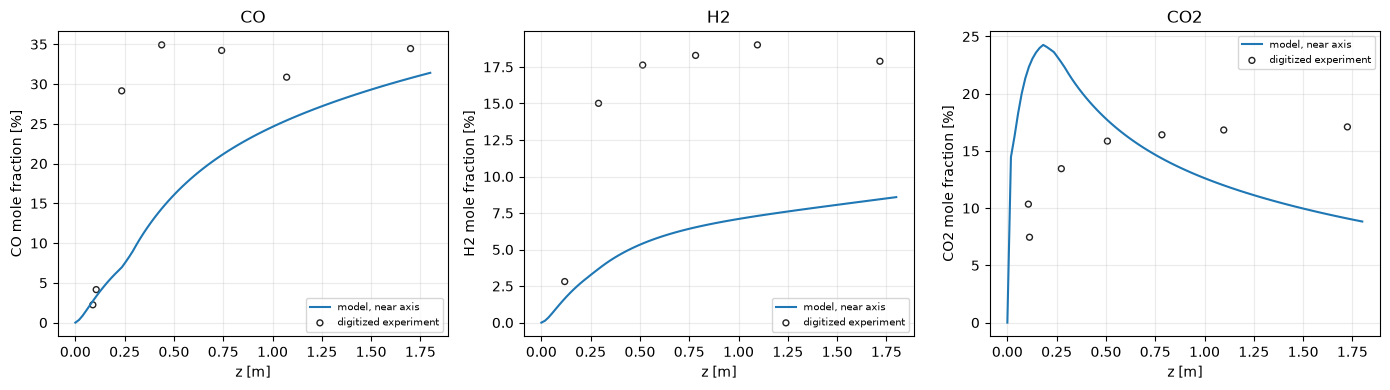

,n,mean abs error [pp],max abs error [pp]
species,,,
CO,7,9.489809,22.193774
H2,6,9.606588,12.215865
CO2,7,7.555347,15.007384


,n,mean abs error [pp],max abs error [pp]
species,,,
CO,34,7.199460,19.297893
H2,36,6.807816,15.371951
CO2,35,6.510085,20.107143


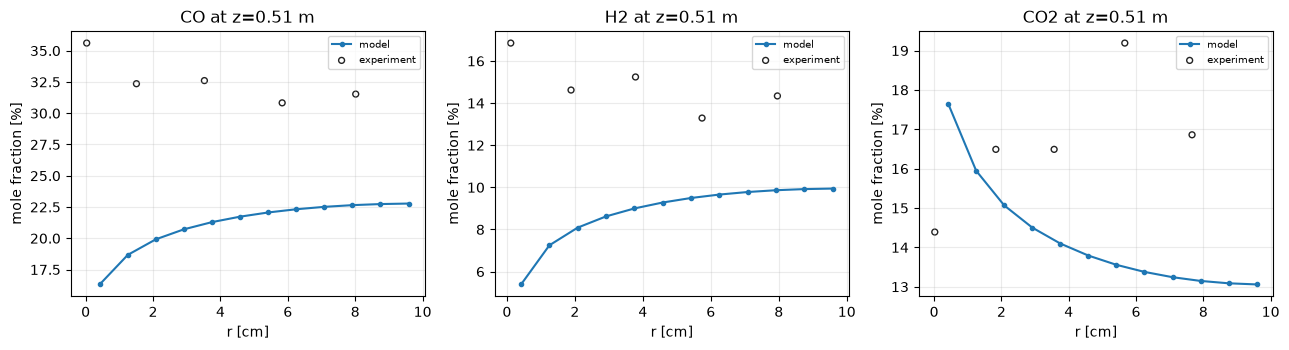

In [12]:
axial=pd.read_csv(ROOT/"data"/"validation"/"fig09_axial_centerline.csv",comment="#")
radial=pd.read_csv(ROOT/"data"/"validation"/"fig12_14_radial_experiment.csv",comment="#")

fig,axs=plt.subplots(1,3,figsize=(14,4))
for ax,s,col in zip(axs,["CO","H2","CO2"],["CO_molfrac_pct","H2_molfrac_pct","CO2_molfrac_pct"]):
    rows=axial.dropna(subset=[col])
    ax.plot(result2["z"],100*result2["x"][s][0],label="model, near axis")
    ax.scatter(rows["z_m"],rows[col],s=18,facecolors="none",edgecolors="#222",label="digitized experiment")
    ax.set(xlabel="z [m]",ylabel=f"{s} mole fraction [%]",title=s); ax.grid(alpha=.25); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

axial_scores=[]
for s,col in [("CO","CO_molfrac_pct"),("H2","H2_molfrac_pct"),("CO2","CO2_molfrac_pct")]:
    rows=axial.dropna(subset=[col]); pred=100*np.interp(rows.z_m,result2["z"],result2["x"][s][0])
    err=np.abs(pred-rows[col].to_numpy())
    axial_scores.append({"species":s,"n":len(err),"mean abs error [pp]":err.mean(),"max abs error [pp]":err.max()})
display(pd.DataFrame(axial_scores).set_index("species"))

# Radial validation at the digitized axial stations and radii.
radial_scores=[]
for s in ["CO","H2","CO2"]:
    rows=radial[radial.species==s]
    pred=[]
    for row in rows.itertuples():
        iz=np.array([np.interp(row.axial_station_m,result2["z"],result2["x"][s][j]) for j in range(NR)])
        pred.append(100*np.interp(row.radius_m,result2["r"],iz))
    err=np.abs(np.asarray(pred)-rows.mole_fraction_pct.to_numpy())
    radial_scores.append({"species":s,"n":len(err),"mean abs error [pp]":err.mean(),"max abs error [pp]":err.max()})
display(pd.DataFrame(radial_scores).set_index("species"))

station=0.51
fig,axs=plt.subplots(1,3,figsize=(13,3.6))
for ax,s in zip(axs,["CO","H2","CO2"]):
    rows=radial[(radial.species==s)&(np.isclose(radial.axial_station_m,station))]
    pred=np.array([np.interp(station,result2["z"],result2["x"][s][j]) for j in range(NR)])*100
    ax.plot(result2["r"]*100,pred,"-o",ms=3,label="model")
    ax.scatter(rows.radius_m*100,rows.mole_fraction_pct,s=18,facecolors="none",edgecolors="#222",label="experiment")
    ax.set(xlabel="r [cm]",ylabel="mole fraction [%]",title=f"{s} at z={station:.2f} m"); ax.grid(alpha=.25); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 14. Particle-size distribution: what the diagnostic can and cannot say

The Rosin–Rammler cumulative mass distribution is `F(d)=1−exp[−(d/dₛ)^q]`, where `dₛ` is the characteristic size and `q` is the spread. It gives the mass fraction below diameter `d`; bin fractions follow by subtracting adjacent CDF values. Smaller particles have greater external area per unit mass (`6/(ρd)` for spheres), so the distribution can estimate how strongly a single 36 μm representative size masks a wide size range.

This is a **diagnostic**, not a particle-size-resolved gasifier simulation. To predict the distribution's effect on conversion, each size class would need its own particle temperature, residence history, devolatilization, and char conversion, then the gas source terms would need to be summed over classes. The current solver uses one representative diameter.

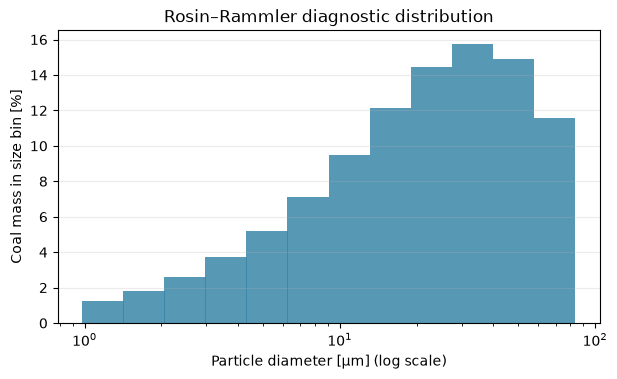

Rosin–Rammler parameters: dscale=36 μm, spread=1.033
Untruncated distribution mean diameter: 35.5 μm; truncated-bin d32 estimate: 10.8 μm
Estimated area/mass over 1–85 μm: 425 m²/kg
36 μm monodisperse area/mass: 128 m²/kg


In [13]:
from scipy.special import gamma
dmin,dmax,ds_um,q=1.0,85.0,36.0,1.033
edges=np.geomspace(dmin,dmax,13)
cdf=lambda d: 1-np.exp(-(d/ds_um)**q)
mass_fraction=np.diff(cdf(edges))
mid=np.sqrt(edges[:-1]*edges[1:])
mass_fraction/=mass_fraction.sum()
mean_d=ds_um*gamma(1+1/q)
d32=1/np.sum(mass_fraction/mid)  # mass-weighted harmonic diameter
rho_p=case["particle_density_kg_m3"]
area_per_kg_bins=np.sum(mass_fraction*6/(rho_p*mid*1e-6))
area_per_kg_36=6/(rho_p*36e-6)
fig,ax=plt.subplots(figsize=(7,3.8))
ax.bar(mid,mass_fraction*100,width=np.diff(edges),align="center",color="#3986a8",alpha=.85)
ax.set_xscale("log"); ax.set(xlabel="Particle diameter [μm] (log scale)",ylabel="Coal mass in size bin [%]",title="Rosin–Rammler diagnostic distribution")
ax.grid(axis="y",alpha=.25); plt.show()
print(f"Rosin–Rammler parameters: dscale={ds_um:g} μm, spread={q:g}")
print(f"Untruncated distribution mean diameter: {mean_d:.1f} μm; truncated-bin d32 estimate: {d32:.1f} μm")
print(f"Estimated area/mass over {dmin:g}–{dmax:g} μm: {area_per_kg_bins:.0f} m²/kg")
print(f"36 μm monodisperse area/mass: {area_per_kg_36:.0f} m²/kg")

## 15. Limitations to say clearly during the demonstration

This solver is useful because each assumption and equation is visible and it connects the actual reference case to predicted species, temperature, and radial profiles. Its limitations should be part of the explanation:

- Gas is ideal and each species uses a constant heat capacity; high-temperature property accuracy is limited.
- The gas species set omits sulfur chemistry and treats ash as inert, so the elemental closure reports C/H/O/N/Ar only.
- Volatile composition uses explicit allocation assumptions and retains surplus carbon in a soot/tar surrogate.
- Char is pure carbon, particle area stays fixed, and representative particle diameter is used.
- Gas-phase kinetics are four global Arrhenius expressions; the eddy-dissipation chemistry coupling in the reference CFD is not reproduced.
- The 1-D calculation assumes plug flow, one gas/particle temperature, instant moisture evaporation, and an ignition enthalpy patch.
- The radial 2-D calculation has annular diffusion and heat exchange but no momentum field, turbulence solution, particle trajectories, recirculation, or radiation.
- In this run, temperature recovery reaches its 4000 K upper bracket. The displayed peak is therefore a numerical ceiling and must not be presented as a resolved peak-temperature prediction.
- The 1-D calculation reaches 100% carbon conversion in this run, which warns that this reduced chemistry and representative-particle closure over-consume modeled solid carbon for the chosen conditions. The atom balance can still close while the prediction is physically inaccurate.
- The radial diffusivity and inlet background spreading are assumptions that should be tested through sensitivity analysis.
- Digitized curves have finite reading uncertainty; agreement in a plot is not proof that every physical process is captured.

These are model boundaries, not hidden defects. State them, explain their likely effects, and point to the measurements used for comparison.

## 16. Viva questions with short answer cues

1. **Why are gas flows stored in mol/s?** Stoichiometric equations conserve atoms and count molecules; molar rates make those balances direct.
2. **Why solve temperature from enthalpy?** With the adiabatic assumption, energy conservation determines temperature as composition changes; the bracketed root solve is stable for stiff chemistry.
3. **What does a stiff ODE mean here?** Reaction and flow timescales differ greatly. An explicit method would need very small steps; LSODA detects stiffness and uses an appropriate method.
4. **Why are volatile split assumptions needed?** Element balances alone do not uniquely determine five gas species from three C/H/O constraints. The assumptions close the system and are disclosed.
5. **What limits char conversion?** Intrinsic chemistry and gas-film diffusion act as resistances in series; whichever is slower dominates.
6. **Where does hydrogen come from?** Coal volatiles, steam-char gasification, water-gas shift, and methane reforming can all contribute; the relative contribution follows the predicted reaction history.
7. **Why does the axial model need an ignition patch?** It lacks the recirculation and radiation that would stabilize a flame; the patch is explicitly an enthalpy adjustment, not a resolved burner.
8. **How does the radial 2-D calculation differ from full CFD?** It resolves annular inlet segregation and radial mixing but has no momentum/turbulence solution or Lagrangian particle tracks.
9. **How do you know the answer is numerically credible?** Check atom balance, nonnegative species, expected axial trends, grid sensitivity, and errors against experimental markers; one check alone is insufficient.
10. **What is the highest-value next improvement?** Resolve particle size and temperature histories, or add validated temperature-dependent thermodynamics and turbulent chemistry coupling; choose based on which data mismatch matters most.

## References

- Mularski, J. & Modlinski, N. (2021). “Entrained-Flow Coal Gasification Process Simulation with the Emphasis on Empirical Char Conversion Models Optimization Procedure.” *Energies*, 14(6), 1729. [Publisher article](https://www.mdpi.com/1996-1073/14/6/1729). BYU case conditions and fitted devolatilization/char parameters are drawn from the published paper.
- Abani, N. & Ghoniem, A. (2013). BYU gasifier injector geometry, as reported for the primary and secondary coaxial streams in *Fuel*, 104.
- Brown et al. (1988). Experimental BYU gasifier measurements attributed by the reference paper and represented here by digitized experimental markers.

---

**End of live walkthrough.** Return to the run summary, select a predicted trend, and ask the audience which model assumption most affects it and what measurement would test that assumption.